In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [318]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=1000, n_features=2, centers=2, random_state=0)
y = y.reshape((y.shape[0], 1))

print('Dimension of X: ', X.shape)
print('Dimension of y: ', y.shape)

Dimension of X:  (1000, 2)
Dimension of y:  (1000, 1)


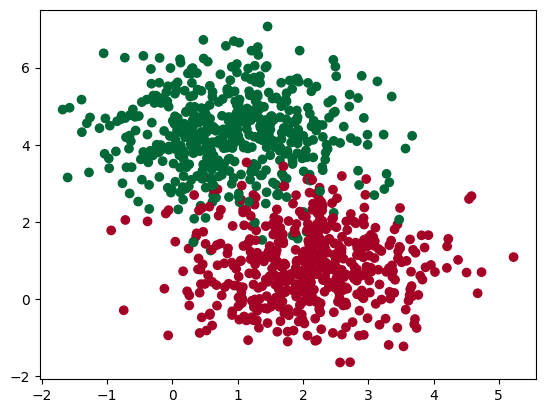

In [319]:
plt.scatter(X[:,0], X[:, 1], c=y, cmap = 'RdYlGn_r')
plt.show()

In [33]:
def initialization(X, y):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    m = len(y)
    return (W,b,m)

In [22]:
def model(X, W,b):
    Z = X.dot(W) + b
    A = 1/ (1+ np.exp(-Z))
    return A

In [34]:
def log_loss(A, y, m):
    return -1/m * np.sum(y*np.log(A) + (1-y) * np.log(1-A))


In [44]:
def gradients(A, X, y, m):
    dW= 1/m * np.dot(X.T, A-y)
    db= 1/m * np.sum(A-y)
    return(dW,db)

In [43]:
def update(W, b, dW, db, learning_rate):
    alpha = learning_rate
    W = W - alpha*dW
    b = b - alpha*db
    return (W,b)

In [234]:
def predict(X, W, b):
    A = model(X,W,b)
    return A >= 0.5, A[0]

In [320]:
def my_neuron(X, y, learning_rate = 0.2, n_iteration =1000):
    W, b, m= initialization(X, y)
    loss = []
    
    for i in range(n_iteration):
        A = model(X, W,b)
        loss.append(log_loss(A, y, m))
        dW, db = gradients(A, X, y, m)
        W, b = update(W, b, dW, db, learning_rate)
    
    y_pred = predict(X, W, b)[0]
    print(accuracy_score(y, y_pred))
    
    
    plt.plot(loss)
    plt.show()
    
    return (W,b)

0.955


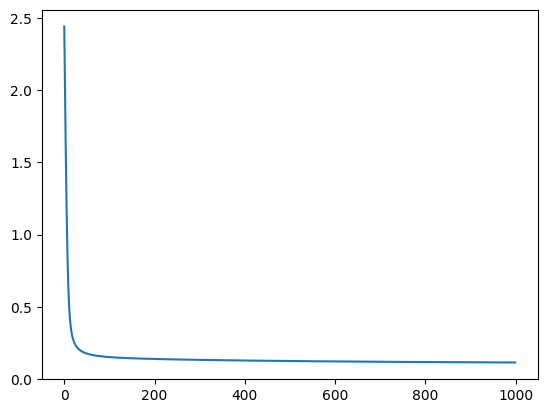

In [327]:
W, b = my_neuron(X, y)

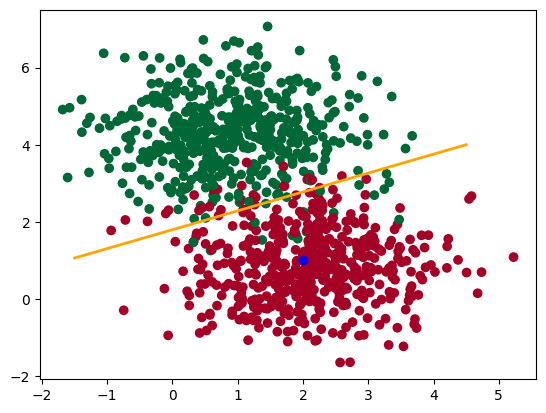

This plant is 98.17 % dangerous


In [328]:
new_plant = np.array([2,1])
new_pred, new_pred_score = predict(new_plant, W,b)
new_pred_score = new_pred_score*100

# decision_boundry
x0= np.linspace(-1.5, 4.5, 100)
x1 = ( -W[0] * x0 - b) / W[1]


plt.scatter(X[:,0], X[:, 1], c=y, cmap = 'RdYlGn_r')
plt.scatter(new_plant[0], new_plant[1], c='b')
plt.plot(x0, x1, c='orange', lw= 2)
plt.show()
print(f"This plant is {new_pred_score:.2f} % dangerous" if new_pred[0] else f"This plant is {100 - new_pred_score:.2f} % safe")